# Lab: Build your first image encoder–decoder

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

**Name:** Utkrisht Suman  
**Roll number:** A24ARIU0001

Revision: completed the missing shape calculations and replaced the old single-run epoch values with a controlled three-model bottleneck experiment. The original network architecture is preserved.


## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [1]:
# %pip install torch torchvision matplotlib


Device: cpu
100.0%
100.0%
100.0%
100.0%
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


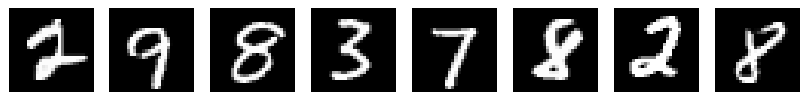

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 64
EPOCHS = 5
LATENT_CHANNELS = 8

print("Device:", device)

# Use the official MNIST mirrors; local downloads are cached for later runs.
datasets.MNIST.mirrors = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
]

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    "./data",
    train=True,
    download=True,
    transform=transform,
)

test_data = datasets.MNIST(
    "./data",
    train=False,
    download=True,
    transform=transform,
)

# Fixed random subsets keep the exercise small and comparisons repeatable
g = torch.Generator().manual_seed(42)

train_indices = torch.randperm(len(train_data), generator=g)[:5000].tolist()

test_indices = torch.randperm(len(test_data), generator=g)[:1000].tolist()

train_data = Subset(train_data, train_indices)
test_data = Subset(test_data, test_indices)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)

test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))

print(
    "Batch:",
    tuple(images.shape),
    "Pixel range:",
    images.min().item(),
    images.max().item(),
)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.show()


## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Answers:**
1. Input values = 28 × 28 = **784**. For L=8, latent values = 8 × 7 × 7 = **392**. The input/latent ratio is **2:1**.
2. For L=32, the latent has 32 × 7 × 7 = **1568** values. This is twice the 784 input values, so it is not dimensionally compressed even though its spatial grid is smaller.
3. `ToTensor()` puts pixels in [0,1]. Sigmoid gives predictions in the same range.
4. With output_padding=0, the first decoder height is (7−1)×2−2×1+(3−1)+0+1 = **13**. With output_padding=1, it becomes 14.

The 1×1 bottleneck mixes channels at each location. It preserves the spatial grid; no flattening or linear layer is needed. The input/latent ratio counts tensor values, not file size or actual encoded bits.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1),
        )

    def forward(self, x):
        return self.network(x)


In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(
                latent_channels,
                16,
                kernel_size=3,
                stride=2,
                padding=1,
                output_padding=1,
            ),
            nn.ReLU(),
            nn.ConvTranspose2d(
                16, 1, kernel_size=3, stride=2, padding=1, output_padding=1
            ),
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)


In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z


In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print(
    "Input:",
    tuple(x.shape),
    "Latent:",
    tuple(z.shape),
    "Output:",
    tuple(reconstruction.shape),
)
print("Shape and range checks passed")


Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [7]:
def train_step(model, images, optimizer, criterion):
    optimizer.zero_grad()

    reconstruction, _ = model(images)

    loss = criterion(reconstruction, images)

    loss.backward()

    optimizer.step()

    return loss.item()


Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04370
Epoch 2: train MSE=0.03428, held-out MSE=0.02552
Epoch 3: train MSE=0.01682, held-out MSE=0.00983
Epoch 4: train MSE=0.00827, held-out MSE=0.00620
Epoch 5: train MSE=0.00572, held-out MSE=0.00460


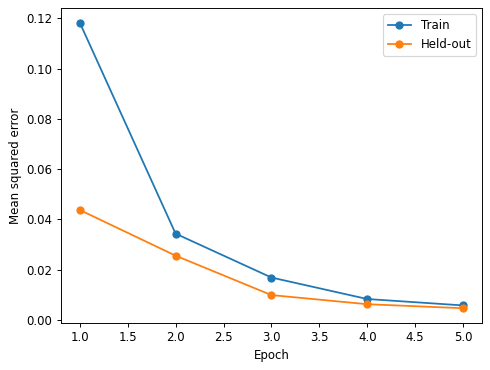

In [8]:
criterion = nn.MSELoss()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)


# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(
        f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
        f"held-out MSE={history['test'][-1]:.5f}"
    )

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()


## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

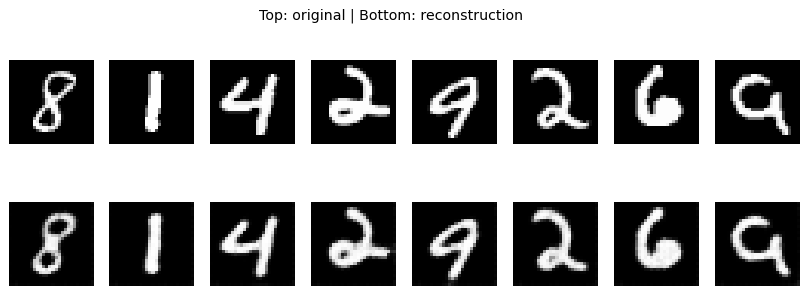

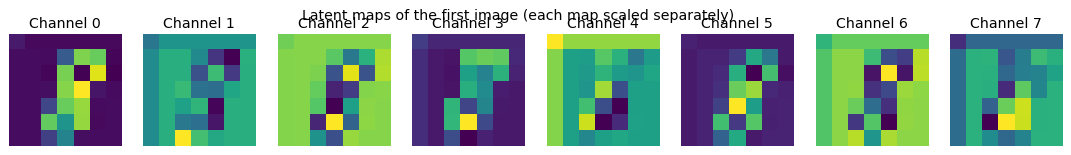

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()


## 6. Experiment with the bottleneck
Three fresh models are trained with L=2, 8, and 32. Each uses the same 5,000 training images, 1,000 held-out images, seed, five epochs, learning rate, batch size, and batch order. The table uses the **final epoch of each separate run**. Parameter counts are shown because changing L also changes model capacity.

The held-out subset is used as validation here because it is inspected repeatedly.


L=2, epoch 1: train=0.180491, held-out=0.090256
L=2, epoch 2: train=0.051612, held-out=0.036220
L=2, epoch 3: train=0.031887, held-out=0.027499
L=2, epoch 4: train=0.021483, held-out=0.014438
L=2, epoch 5: train=0.012821, held-out=0.010753
L=8, epoch 1: train=0.118521, held-out=0.043603
L=8, epoch 2: train=0.034414, held-out=0.026156
L=8, epoch 3: train=0.017354, held-out=0.010108
L=8, epoch 4: train=0.008350, held-out=0.006112
L=8, epoch 5: train=0.005623, held-out=0.004552
L=32, epoch 1: train=0.119585, held-out=0.031334
L=32, epoch 2: train=0.016911, held-out=0.009614
L=32, epoch 3: train=0.007883, held-out=0.005541
L=32, epoch 4: train=0.004931, held-out=0.003867
L=32, epoch 5: train=0.003634, held-out=0.003058

L | latent values | input/latent | parameters | final train MSE | final held-out MSE
 2 |   98 | 8.00 | 5315 | 0.012821 | 0.010753
 8 |  392 | 2.00 | 6377 | 0.005623 | 0.004552
32 | 1568 | 0.50 | 10625 | 0.003634 | 0.003058


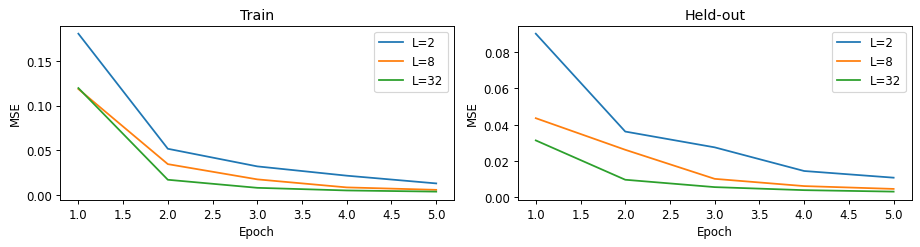

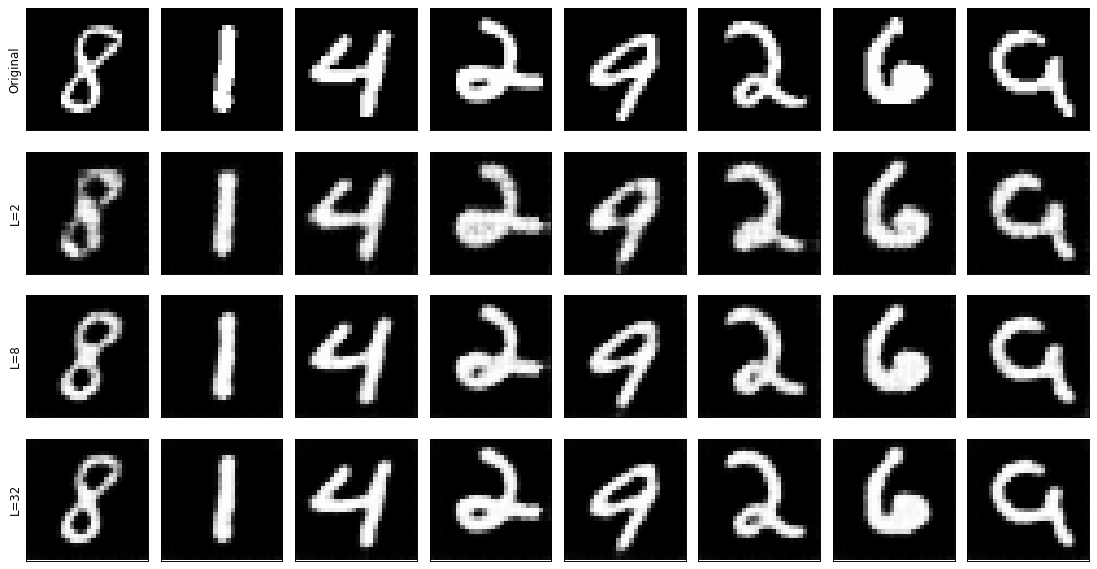

In [10]:
import json
from pathlib import Path

experiment_results = []
experiment_models = {}
experiment_histories = {}
for channels in (2, 8, 32):
    torch.manual_seed(42)
    run_model = ImageEncoderDecoder(channels).to(device)
    run_optimizer = torch.optim.Adam(run_model.parameters(), lr=1e-3)
    run_loader = DataLoader(
        train_data,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42),
    )
    run_history = {"train": [], "held_out": []}
    for epoch in range(EPOCHS):
        run_model.train()
        total = 0.0
        for batch, _ in run_loader:
            batch = batch.to(device)
            total += train_step(run_model, batch, run_optimizer, criterion) * len(batch)
        train_mse = total / len(train_data)
        held_out_mse = evaluate(run_model, test_loader)
        run_history["train"].append(train_mse)
        run_history["held_out"].append(held_out_mse)
        print(
            f"L={channels}, epoch {epoch+1}: train={train_mse:.6f}, held-out={held_out_mse:.6f}"
        )
    experiment_results.append(
        {
            "channels": channels,
            "values": channels * 7 * 7,
            "ratio": 784 / (channels * 7 * 7),
            "train_mse": train_mse,
            "held_out_mse": held_out_mse,
            "parameters": sum(p.numel() for p in run_model.parameters()),
        }
    )
    experiment_models[channels] = run_model.cpu().eval()
    experiment_histories[channels] = run_history

print(
    "\nL | latent values | input/latent | parameters | final train MSE | final held-out MSE"
)
for row in experiment_results:
    print(
        f"{row['channels']:2d} | {row['values']:4d} | {row['ratio']:.2f} | {row['parameters']} | "
        f"{row['train_mse']:.6f} | {row['held_out_mse']:.6f}"
    )
Path("lab1_bottleneck_results.json").write_text(
    json.dumps(experiment_results, indent=2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for channels in (2, 8, 32):
    history_l = experiment_histories[channels]
    axes[0].plot(range(1, EPOCHS + 1), history_l["train"], label=f"L={channels}")
    axes[1].plot(range(1, EPOCHS + 1), history_l["held_out"], label=f"L={channels}")
for ax, title in zip(axes, ["Train", "Held-out"]):
    ax.set(xlabel="Epoch", ylabel="MSE", title=title)
    ax.legend()
plt.tight_layout()
plt.show()

fixed_images, _ = next(iter(test_loader))
fixed_images = fixed_images[:8]
fig, axes = plt.subplots(4, 8, figsize=(13, 7))
for i in range(8):
    axes[0, i].imshow(fixed_images[i, 0], cmap="gray", vmin=0, vmax=1)
for row_index, channels in enumerate((2, 8, 32), start=1):
    with torch.no_grad():
        reconstructed_l, _ = experiment_models[channels](fixed_images)
    for i in range(8):
        axes[row_index, i].imshow(reconstructed_l[i, 0], cmap="gray", vmin=0, vmax=1)
for row_index, label in enumerate(["Original", "L=2", "L=8", "L=32"]):
    axes[row_index, 0].set_ylabel(label)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()


### Experiment table and discussion

All three models were freshly initialized with seed 42 and trained for five epochs.

| L | Latent values | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---:|---:|---:|---:|---:|---|
| 2 | 98 | 8:1 | 0.012821 | 0.010753 | Digits are recognizable, but edges are blurred; the 4 loses some shape and the 9 has a thick loop. |
| 8 | 392 | 2:1 | 0.005623 | 0.004552 | Holes and strokes are clearer than L=2, including the 8 and 9; some fine detail remains smooth. |
| 32 | 1568 | 0.5:1 | 0.003634 | 0.003058 | Closest to the originals in this grid, with sharper curves and better preservation of narrow gaps. |

1. **Did a larger latent improve reconstruction?** Yes in this run. Held-out MSE decreased from 0.010753 for L=2 to 0.004552 for L=8 and 0.003058 for L=32. In the shared image grid, L=2 gives thicker, blurred strokes, while L=8 and L=32 preserve the holes in the 8 and 9 more clearly. L=32 gives the closest overall match among these examples. This does not prove that increasing L always helps: the parameter counts also rise from 5,315 to 6,377 and 10,625, and only one seed was tested.

2. **Why is spatial downsampling not enough to claim compression?** Total values depend on channels as well as height and width. L=32 has 32×7×7=1,568 values, which is more than the 784 input pixels despite the smaller spatial grid. L=2 has 98 values and L=8 has 392, so those two are dimensionally compressed.

3. **Why can size be restored without every detail?** Transposed convolutions learn to produce a larger grid. Downsampling and the bottleneck can discard information, so restoring 28×28 dimensions cannot guarantee that every original stroke or edge is recovered. The remaining blur in the reconstructions shows this difference.

4. **How would a 128-value vector differ?** A `[N,128]` vector has 128 values per image and no explicit 7×7 spatial grid. The current `[N,L,7,7]` representation retains spatial arrangement, so convolutions can process nearby positions. A vector would normally need a linear/reshape step before the convolutional decoder. Neither format guarantees that individual features have a simple interpretation.

5. **Where could a skip connection go?** Encoder features at 14×14 could connect to decoder features at the matching 14×14 resolution, using addition or concatenation with a suitable channel adjustment. This could preserve edges, but it would also let information bypass the 7×7 bottleneck, weakening its compression constraint.

6. **Why is this not a reliable random-image generator?** Training only teaches the decoder to reconstruct latent codes produced by the encoder. There is no constraint that makes those codes follow a known distribution such as a standard normal. Randomly sampled latent tensors may fall outside the learned region and decode poorly. A VAE adds a probabilistic encoder and a prior-related regularization term for this purpose.


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.